# 05 Fine-tuning the encoder

In notebooks 02 to 04, every model used frozen BERT vectors: the encoder turned each chunk of Item 7 into a vector
once, and only the model on top was trained. Two different encoders (`ProsusAI/finbert` and Yang et al.'s FinBERT),
two kinds of vector (CLS and token average) and two models (ridge and the attention network) all gave the same small
gain over the straight line. The option left is to train the encoder itself on our target, so that it can learn
which parts of the text matter for volatility. This is fine-tuning, which the brief lists alongside transfer
learning, and it is what FETILDA (Xia et al., 2022) did.

Fine-tuning is much more expensive than anything so far, so this notebook is a **demonstration on one test year**,
not a full rerun:

| What | Frozen vectors (notebooks 02 to 04) | Here |
|---|---|---|
| Encoder | Fixed | Yang et al.'s FinBERT, every weight trained |
| Model on top | Ridge, or the attention network | One linear layer on the report's average chunk vector |
| Target | Within-year residual of the straight line | The same |
| Test years | 2001 to 2006, both windows | 2006, paper window (train 2001 to 2004, early stopping on 2005) |
| Seeds | 5 | 1 |
| Reading a report | Every chunk | 4 random chunks per report per training step; every chunk to predict |

The model on top is deliberately the simplest: if fine-tuning helps, it should show even with a linear head, and the
comparison with the frozen ridge on Yang's token averages (notebook 04) is then like for like, apart from the encoder
being trained.

**This runs on a Colab GPU, in two stages.** With `GO = False` (section 2), Run all only sets up, checks the model
and times a few training steps, and stops. After the checks have been looked at, set `GO = True` and Run all again:
it fine-tunes for up to 3 epochs (about 1.5 to 2 hours on a T4, resumable after each epoch), saving everything to
Google Drive.

## 1. Setup

As in notebook 04: on Colab, install pandas 3 (for `data.pkl`), connect Google Drive, get the repo, and link Oscar's
Item 7 text (`sprint2-data/text`) into the places his `Oscar/extract_finbert.py` reads from.

In [15]:
import importlib.metadata, importlib.util, os, shutil, subprocess, sys
from pathlib import Path

NOTEBOOK_DIR = "Alex"
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB:
    # data.pkl was written with pandas 3 and Colab ships pandas 2, which cannot read it.
    if int(importlib.metadata.version("pandas").split(".")[0]) < 3:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pandas==3.0.6"], check=True)
        if "pandas" in sys.modules:
            print("pandas 3 installed but the old one was already loaded: restarting the runtime. Run all again.")
            os.kill(os.getpid(), 9)
    from google.colab import drive
    drive.mount("/content/drive")
    repo = Path("/content/dst-sprint2")
    if repo.exists():
        subprocess.run(["git", "-C", str(repo), "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", "https://github.com/Oscar339/dst-sprint2.git", str(repo)], check=True)
    processed = repo / "data" / "processed"
    processed.mkdir(parents=True, exist_ok=True)
    if not (processed / "data.pkl").exists():
        shutil.copy(Path("/content/drive/MyDrive/sprint2-data/data.pkl"), processed / "data.pkl")
    os.chdir(repo / NOTEBOOK_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
import copy, math, pickle, platform, time, urllib.request
sys.path.insert(0, "."); sys.path.insert(0, "../Oscar")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display

import scoring

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Python {platform.python_version()} | torch {torch.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))

with open("../data/processed/data.pkl", "rb") as f:
    d = pickle.load(f)
df = scoring.frame(d)
x_all, y_all, yr_all = df["logvol_before"].to_numpy(), df["logvol_after"].to_numpy(), df["year"].to_numpy()
print(f"{len(df):,} reports, {df.year.min()}-{df.year.max()}")

DRIVE = Path("/content/drive/MyDrive/sprint2-data")
TEXT_DIR = DRIVE / "text"                      # Oscar's shared folder: edgar_matched/ and item7_source.csv
OUT_DIR = DRIVE / "fine-tuning"                # everything this notebook makes; survives the session
TOK_DIR = OUT_DIR / "tokens"                   # Item 7 word pieces, cut into chunks, one file per year
RESULTS_FILE, HISTORY_FILE = OUT_DIR / "alex-05-results.csv", OUT_DIR / "alex-05-history.csv"
TIMING_FILE = OUT_DIR / "alex-05-timing.csv"

PROCESSED, KOGAN = Path("../data/processed"), Path("../data/raw/kogan")
if IN_COLAB:
    assert (TEXT_DIR / "item7_source.csv").exists() and (TEXT_DIR / "edgar_matched").exists(), \
        f"Oscar's text is not in {TEXT_DIR}: add the shared folder to My Drive as sprint2-data/text"
    shutil.copy(TEXT_DIR / "item7_source.csv", PROCESSED / "item7_source.csv")
    if not (PROCESSED / "edgar_matched").exists():
        (PROCESSED / "edgar_matched").symlink_to(TEXT_DIR / "edgar_matched")
    KOGAN.mkdir(parents=True, exist_ok=True)
    for yr in range(1996, 2007):
        target = KOGAN / f"{yr}.tok.tgz"
        if not target.exists():
            urllib.request.urlretrieve(f"https://www.cs.cmu.edu/~ark/10K/data/{target.name}", target)
    TOK_DIR.mkdir(parents=True, exist_ok=True)
    print("edgar_matched files:", len(list((PROCESSED / "edgar_matched").glob("*.jsonl.gz"))),
          "| Kogan text files:", len(list(KOGAN.glob("*.tok.tgz"))))

Python 3.13.16 | torch 2.14.1+cu130 | device cuda (Tesla T4)
27,142 reports, 1996-2006
edgar_matched files: 11 | Kogan text files: 11


## 2. Settings, the model, and checks before running

**Settings.** Fine-tuning a BERT model is usually done with a small learning rate for the encoder (here $2\times10^{-5}$),
a short warm-up in which the learning rate rises from zero, then a linear decay, for 2 to 4 epochs (Devlin et al.,
2019; Sun et al., 2019). The new layer on top gets a larger learning rate ($10^{-3}$), since it starts from nothing.
The weights are updated by gradient descent on the MSE (lecture 06.1, slides 15 and 16), with AdamW as in notebook
03, and the gradient is clipped so one bad batch cannot throw the encoder far from where it started. Training runs
in mixed precision (Micikevicius et al., 2018): the weights are kept in 32-bit, but most of the arithmetic is done in
16-bit, which is what a T4 is fast at.

**Reading a report.** A report has 15 chunks at the median and up to 64, and every chunk in a training step has to go
through the encoder twice (forwards and backwards). So each training step reads a random 4 of each report's chunks,
averages their vectors and predicts from the average; each epoch draws a new 4. The average of a random 4 is an
unbiased estimate of the average of all of them, so to predict, the model reads every chunk, exactly as the frozen
models did. Averaging is the simplest pooling layer (lecture 06.2, slide 12).

**Starting point.** The new layer starts at zero, so before any training the model predicts no text effect at all,
which is exactly the straight line. Early stopping keeps the epoch with the lowest MSE on the last training year
(2005); if no epoch beats the straight line there, the text is switched off, the same rule the ridge uses when the
last training year chooses the largest $\lambda$.

In [17]:
GO = True          # False: checks only. Set to True once the checks below look right, then Run all again.

from huggingface_hub import hf_hub_download
from tokenizers import BertWordPieceTokenizer
from transformers import BertModel, PreTrainedTokenizerFast
from extract_finbert import CHUNK, MAX_CHUNKS, load_plan, load_texts   # Oscar's chunk size, cap and text rules

TEST_YEAR, WINDOW, SEEDS = 2006, "paper", [0]
FT = dict(chunks_per_report=4,      # chunks read per report in each training step
          micro_reports=2,          # reports per pass through the GPU (8 chunks), to fit in memory
          reports_per_step=16,      # reports per weight update (gradients added over 8 passes)
          max_epochs=3, lr_encoder=2e-5, lr_head=1e-3, weight_decay=0.01, warmup=0.1, clip=1.0,
          dropout=0.1, eval_chunks=32)

YANG, REVISION = "yiyanghkust/finbert-pretrain", "88ab954a39ea6d3ce2b62cff086dd5ad1172c664"
# As in notebook 04: built from the vocabulary, because transformers 5 ignores vocab_file= in BertTokenizerFast.
tok = PreTrainedTokenizerFast(
    tokenizer_object=BertWordPieceTokenizer(hf_hub_download(YANG, "vocab.txt", revision=REVISION), lowercase=True),
    unk_token="[UNK]", sep_token="[SEP]", pad_token="[PAD]", cls_token="[CLS]", mask_token="[MASK]")
tok.model_max_length = 10 ** 9
assert tok.vocab_size == 30_873, "the tokenizer did not load Yang's vocabulary"
CLS_ID, SEP_ID, PAD_ID = tok.cls_token_id, tok.sep_token_id, tok.pad_token_id

def load_encoder():
    # 32-bit weights: they are trained, and mixed precision does the 16-bit arithmetic
    return BertModel.from_pretrained(YANG, revision=REVISION, dtype=torch.float32, add_pooling_layer=False)


class FineTuned(nn.Module):
    # Yang's FinBERT -> token average per chunk -> average over the report's chunks -> one linear layer
    def __init__(self, encoder, dropout=0.1):
        super().__init__()
        self.encoder = encoder
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(encoder.config.hidden_size, 1)
        nn.init.zeros_(self.head.weight); nn.init.zeros_(self.head.bias)    # starts at "no text effect"

    def chunk_vectors(self, ids, mask):
        with torch.autocast("cuda", dtype=torch.float16, enabled=ids.is_cuda):
            h = self.encoder(input_ids=ids, attention_mask=mask).last_hidden_state
        m = mask.unsqueeze(-1).to(h.dtype)
        return ((h * m).sum(1) / m.sum(1)).float()

    def forward(self, ids, mask, owner, n_reports):
        v = self.chunk_vectors(ids, mask)
        pooled = torch.zeros(n_reports, v.shape[1], device=v.device).index_add_(0, owner, v)
        pooled = pooled / torch.bincount(owner, minlength=n_reports).unsqueeze(1).float()
        return self.head(self.drop(pooled)).squeeze(-1)


def chunk_report(text):
    ids = tok(text, add_special_tokens=False)["input_ids"]
    return [np.array(ids[i:i + CHUNK], dtype=np.uint16) for i in range(0, len(ids), CHUNK)][:MAX_CHUNKS]

def pad(chunk_list):
    L = max(len(c) for c in chunk_list) + 2
    ids = torch.full((len(chunk_list), L), PAD_ID, dtype=torch.long)
    mask = torch.zeros((len(chunk_list), L), dtype=torch.long)
    for k, c in enumerate(chunk_list):
        ids[k, :len(c) + 2] = torch.tensor([CLS_ID, *c.tolist(), SEP_ID]); mask[k, :len(c) + 2] = 1
    return ids.to(DEVICE), mask.to(DEVICE)

def train_batch(chunks, idx, rng, k):
    # k random chunks from each report in idx (all of them if it has k or fewer)
    picked, owner = [], []
    for j, i in enumerate(idx):
        for c in rng.choice(len(chunks[i]), size=min(k, len(chunks[i])), replace=False):
            picked.append(chunks[i][c]); owner.append(j)
    ids, mask = pad(picked)
    return ids, mask, torch.tensor(owner, device=DEVICE)

@torch.no_grad()
def predict_reports(model, chunks, idx, batch=32):
    # every chunk of every report in idx; returns the model's prediction per report
    model.eval()
    flat = [(j, c) for j, i in enumerate(idx) for c in chunks[i]]
    sums = torch.zeros(len(idx), model.head.in_features, device=DEVICE)
    counts = torch.zeros(len(idx), device=DEVICE)
    for s in range(0, len(flat), batch):
        part = flat[s:s + batch]
        owner = torch.tensor([j for j, _ in part], device=DEVICE)
        v = model.chunk_vectors(*pad([c for _, c in part]))
        sums.index_add_(0, owner, v); counts.index_add_(0, owner, torch.ones(len(part), device=DEVICE))
    return model.head(sums / counts.unsqueeze(1)).squeeze(-1).cpu().numpy()

def make_optimizer(model, steps_total):
    decay, no_decay = [], []
    for n, p in model.encoder.named_parameters():
        (no_decay if n.endswith("bias") or "LayerNorm" in n else decay).append(p)
    opt = torch.optim.AdamW([
        {"params": decay, "lr": FT["lr_encoder"], "weight_decay": FT["weight_decay"]},
        {"params": no_decay, "lr": FT["lr_encoder"], "weight_decay": 0.0},
        {"params": model.head.parameters(), "lr": FT["lr_head"], "weight_decay": 0.0}])
    warm = max(1, int(FT["warmup"] * steps_total))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min((s + 1) / warm, max(0.0, (steps_total - s) / max(1, steps_total - warm))))
    return opt, sched

print(f"settings: {FT}")
print(f"test year {TEST_YEAR}, {WINDOW} window: train {scoring.WINDOWS[WINDOW](TEST_YEAR)}, seeds {SEEDS}")

settings: {'chunks_per_report': 4, 'micro_reports': 2, 'reports_per_step': 16, 'max_epochs': 3, 'lr_encoder': 2e-05, 'lr_head': 0.001, 'weight_decay': 0.01, 'warmup': 0.1, 'clip': 1.0, 'dropout': 0.1, 'eval_chunks': 32}
test year 2006, paper window: train range(2001, 2006), seeds [0]


**Checks.** On 32 reports from 2006: that the untrained model predicts exactly zero (the straight line), that a few
training steps change the encoder's weights and bring the loss down on those reports, how much GPU memory a step
takes, and how fast training and prediction run. The timings give the estimate for the full run. The checks train a
copy of the model, which is then thrown away.

In [18]:
plan = load_plan()
assert set(plan["key"]) == set(df["key"]), "the reports must be exactly the reports in data.pkl"
key_row = {k: i for i, k in enumerate(df["key"])}
rows_check = plan[plan["year"] == 2006].head(32)
texts_check = load_texts(2006, rows_check)
check_chunks = {key_row[k]: chunk_report(texts_check[k][1]) for k in rows_check["key"]}
check_idx = np.array(list(check_chunks))
z = (y_all - y_all.mean()) / y_all.std()                    # any target will do to see the loss fall

torch.manual_seed(0)
model = FineTuned(load_encoder(), FT["dropout"]).to(DEVICE)
print(f"encoder: {sum(p.numel() for p in model.encoder.parameters()) / 1e6:.0f}M parameters, all trained")
p0 = predict_reports(model, check_chunks, check_idx[:4])
assert np.all(p0 == 0), "the untrained model should predict exactly zero"
print("untrained prediction is exactly zero: the model starts at the straight line")

# a bias: weight decay does not touch it, so it only changes if a gradient reaches the encoder
before = model.encoder.encoder.layer[0].attention.self.query.bias.detach().clone()
opt, sched = make_optimizer(model, 100)
scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
rng = np.random.default_rng(0)
fixed = check_idx[:FT["micro_reports"]]
if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()
losses, n_chunks, t_train = [], 0, 0.0
for step in range(24):
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    model.train()
    ids, mask, owner = train_batch(check_chunks, fixed, rng, FT["chunks_per_report"])
    opt.zero_grad(set_to_none=True)
    loss = ((model(ids, mask, owner, len(fixed)) - torch.tensor(z[fixed], dtype=torch.float32, device=DEVICE)) ** 2).mean()
    scaler.scale(loss).backward()
    scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), FT["clip"])
    scaler.step(opt); scaler.update(); sched.step()
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    if step >= 4:                                            # the first steps include warm-up costs
        t_train += time.perf_counter() - t0; n_chunks += len(ids)
    losses.append(loss.item())
changed = (model.encoder.encoder.layer[0].attention.self.query.bias - before).abs().max().item()
train_rate = n_chunks / t_train
peak = torch.cuda.max_memory_allocated() / 2 ** 30 if DEVICE == "cuda" else float("nan")
print(f"loss on 2 reports: {np.mean(losses[:3]):.3f} at the start -> {np.mean(losses[-3:]):.3f} after 24 steps; "
      f"largest change to a first-layer bias {changed:.1e}")
assert changed > 0, "the encoder's weights did not change: it is not being trained"

if DEVICE == "cuda":
    torch.cuda.synchronize()
t0 = time.perf_counter()
predict_reports(model, check_chunks, check_idx, FT["eval_chunks"])
if DEVICE == "cuda":
    torch.cuda.synchronize()
eval_rate = sum(len(c) for c in check_chunks.values()) / (time.perf_counter() - t0)
print(f"training {train_rate:.0f} chunks/s | predicting {eval_rate:.0f} chunks/s | peak GPU memory {peak:.1f} GB")
del model, opt, sched, scaler
if DEVICE == "cuda":
    torch.cuda.empty_cache()

# Estimate the full run from the first encoder's chunk counts, scaled by Yang's 4% fewer word pieces (notebook 04)
train_mask, test_mask = scoring.masks(df, TEST_YEAR, WINDOW)
years = scoring.WINDOWS[WINDOW](TEST_YEAR)
n_chunks_all = np.array([len(c) for c in d["X_item7"]]) * 480_332 / 498_607
fit_mask, val_mask = train_mask & (yr_all != years[-1]), train_mask & (yr_all == years[-1])
per_epoch = (np.minimum(n_chunks_all[fit_mask], FT["chunks_per_report"]).sum() / train_rate
             + n_chunks_all[val_mask].sum() / eval_rate)
total = FT["max_epochs"] * per_epoch + n_chunks_all[test_mask].sum() / eval_rate
print(f"fit {fit_mask.sum():,} reports, early stopping {val_mask.sum():,}, test {test_mask.sum():,}: "
      f"about {per_epoch / 60:.0f} min per epoch, {total / 3600:.1f} hours for {FT['max_epochs']} epochs per seed")
timing = pd.DataFrame([{"device": DEVICE, "train_chunks_per_second": train_rate, "predict_chunks_per_second": eval_rate,
                        "peak_memory_gb": peak, "minutes_per_epoch_estimate": per_epoch / 60}])
if IN_COLAB:
    timing.to_csv(TIMING_FILE, index=False)
if not GO:
    print("\nGO is False: checks done, nothing fine-tuned. Set GO = True above and Run all again.")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: yiyanghkust/finbert-pretrain
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


encoder: 109M parameters, all trained
untrained prediction is exactly zero: the model starts at the straight line
loss on 2 reports: 0.267 at the start -> 0.004 after 24 steps; largest change to a first-layer bias 2.2e-04
training 34 chunks/s | predicting 162 chunks/s | peak GPU memory 3.0 GB
fit 11,271 reports, early stopping 3,121, test 3,003: about 29 min per epoch, 1.6 hours for 3 epochs per seed


## 3. The text

Item 7 for the six years needed (2001 to 2006), cut into chunks of 510 word pieces, at most 64 per report, with
Oscar's rules for which text to read, exactly as in notebook 04. The word pieces are saved to Drive one year at a
time, so a rerun does not read the text again.

In [19]:
CHUNKS = None
if GO and IN_COLAB and DEVICE == "cuda":
    CHUNKS = [None] * len(df)
    for yr in sorted(set(years) | {TEST_YEAR}):
        path = TOK_DIR / f"{yr}.npz"
        if not path.exists():
            rows_y = plan[plan["year"] == yr]
            texts = load_texts(yr, rows_y)
            per = [chunk_report(texts[k][1]) for k in rows_y["key"]]
            tmp = TOK_DIR / f"{yr}.tmp.npz"
            np.savez(tmp, keys=np.array(rows_y["key"]), n=np.array([len(p) for p in per]),
                     lens=np.array([len(c) for p in per for c in p]),
                     ids=np.concatenate([c for p in per for c in p]))
            os.replace(tmp, path)
        zf = np.load(path, allow_pickle=True)
        pieces = np.split(zf["ids"], np.cumsum(zf["lens"])[:-1])
        starts = np.concatenate([[0], np.cumsum(zf["n"])[:-1]])
        for k, s0, n in zip(zf["keys"], starts, zf["n"]):
            CHUNKS[key_row[str(k)]] = pieces[s0:s0 + n]
        print(f"{yr}: {len(zf['keys']):,} reports, {zf['n'].sum():,} chunks", flush=True)
    needed = np.flatnonzero(train_mask | test_mask)
    assert all(CHUNKS[i] is not None and len(CHUNKS[i]) > 0 for i in needed), "every report needs Item 7 chunks"
else:
    print("skipped (GO is False, or not on a Colab GPU)")

2001: 2,299 reports, 36,202 chunks
2002: 2,587 reports, 49,898 chunks
2003: 3,217 reports, 69,172 chunks
2004: 3,168 reports, 73,724 chunks
2005: 3,121 reports, 70,266 chunks
2006: 3,003 reports, 67,746 chunks


## 4. Fine-tuning

The target is the one the attention network used (notebook 03): what the straight line gets wrong, with each
training year's average taken out, scaled to standard deviation 1. After each epoch, the model is scored on 2005, and
the model, the optimiser and the history are saved to Drive, so a session that stops carries on from the last
finished epoch. The random chunks drawn in each epoch depend only on the seed and the epoch, so a resumed run draws
the same ones.

In [20]:
def fine_tune(seed, fit_idx, val_idx, target, tag):
    ckpt, best_path = OUT_DIR / f"{tag}_checkpoint.pt", OUT_DIR / f"{tag}_best.pt"
    torch.manual_seed(seed)
    model = FineTuned(load_encoder(), FT["dropout"]).to(DEVICE)
    steps_per_epoch = math.ceil(len(fit_idx) / FT["reports_per_step"])
    opt, sched = make_optimizer(model, steps_per_epoch * FT["max_epochs"])
    scaler = torch.amp.GradScaler("cuda")
    history, best, start = [], (float(np.mean(target[val_idx] ** 2)), -1), 0   # epoch -1: text switched off
    if ckpt.exists():
        state = torch.load(ckpt, map_location=DEVICE, weights_only=False)
        model.load_state_dict(state["model"]); opt.load_state_dict(state["opt"])
        sched.load_state_dict(state["sched"]); scaler.load_state_dict(state["scaler"])
        history, best, start = state["history"], state["best"], state["epoch"]
        print(f"resuming after epoch {start}")
    t_all = torch.tensor(target, dtype=torch.float32, device=DEVICE)
    for epoch in range(start, FT["max_epochs"]):
        rng = np.random.default_rng([seed, epoch])
        torch.manual_seed(1000 * seed + epoch)
        order = rng.permutation(fit_idx)
        model.train()
        t0, total, n_chunks = time.perf_counter(), 0.0, 0
        for step, s in enumerate(range(0, len(order), FT["reports_per_step"])):
            step_idx = order[s:s + FT["reports_per_step"]]
            opt.zero_grad(set_to_none=True)
            for m0 in range(0, len(step_idx), FT["micro_reports"]):
                b = step_idx[m0:m0 + FT["micro_reports"]]
                ids, mask, owner = train_batch(CHUNKS, b, rng, FT["chunks_per_report"])
                pred = model(ids, mask, owner, len(b))
                loss = ((pred - t_all[torch.as_tensor(b, device=DEVICE)]) ** 2).sum() / len(step_idx)
                scaler.scale(loss).backward()
                total += loss.item() * len(step_idx); n_chunks += len(ids)
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), FT["clip"])
            scaler.step(opt); scaler.update(); sched.step()
            if step % 100 == 0:
                print(f"  epoch {epoch + 1} step {step}/{steps_per_epoch}: "
                      f"{n_chunks / (time.perf_counter() - t0):.0f} chunks/s", flush=True)
        train_seconds = time.perf_counter() - t0
        t0 = time.perf_counter()
        val_mse = float(np.mean((predict_reports(model, CHUNKS, val_idx, FT["eval_chunks"]) - target[val_idx]) ** 2))
        history.append({"seed": seed, "epoch": epoch + 1, "train_mse": total / len(fit_idx), "val_mse": val_mse,
                        "val_mse_text_off": float(np.mean(target[val_idx] ** 2)),
                        "train_seconds": train_seconds, "train_chunks": n_chunks,
                        "val_seconds": time.perf_counter() - t0})
        print(f"epoch {epoch + 1}: train MSE {history[-1]['train_mse']:.4f}, 2005 MSE {val_mse:.4f} "
              f"(text off: {history[-1]['val_mse_text_off']:.4f}), {train_seconds / 60:.0f} min", flush=True)
        if val_mse < best[0]:
            best = (val_mse, epoch)
            torch.save(model.state_dict(), OUT_DIR / f"{tag}_best.tmp.pt"); os.replace(OUT_DIR / f"{tag}_best.tmp.pt", best_path)
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "scaler": scaler.state_dict(), "history": history, "best": best, "epoch": epoch + 1},
                   OUT_DIR / f"{tag}_checkpoint.tmp.pt")
        os.replace(OUT_DIR / f"{tag}_checkpoint.tmp.pt", ckpt)
    if best[1] < 0:
        print("no epoch beat the straight line on 2005: text switched off")
        return None, history
    model.load_state_dict(torch.load(best_path, map_location=DEVICE))
    print(f"kept epoch {best[1] + 1} (2005 MSE {best[0]:.4f})")
    return model, history


def make_finetuned(seed, history_log):
    # a predict(df, train, test) for scoring.evaluate, with the same target and centring as attention.py
    def predict(df_, train, test):
        yrs = sorted(set(yr_all[train]))
        fit, val = train & (yr_all != yrs[-1]), train & (yr_all == yrs[-1])
        fit_idx, val_idx, test_idx = np.flatnonzero(fit), np.flatnonzero(val), np.flatnonzero(test)
        a, b = scoring.fit_line(df_, train)
        resid = y_all - (a + b * x_all)
        resid = resid - pd.Series(resid).groupby(yr_all).transform("mean").where(train, 0).to_numpy()
        scale = resid[fit_idx].std()
        tag = f"yang_{WINDOW}_{TEST_YEAR}_seed{seed}"
        model, history = fine_tune(seed, fit_idx, val_idx, resid / scale, tag)
        history_log.extend(history)
        if model is None:
            text = np.zeros(len(test_idx))
        else:
            t0 = time.perf_counter()
            text = predict_reports(model, CHUNKS, test_idx, FT["eval_chunks"]) * scale
            text = text - text.mean()                                   # centre on the test year
            print(f"predicted {len(test_idx):,} test reports in {(time.perf_counter() - t0) / 60:.0f} min")
            del model
            torch.cuda.empty_cache()
        return a + b * x_all[test_idx] + text
    return predict


if CHUNKS is not None:
    done = pd.read_csv(RESULTS_FILE)["model"].tolist() if RESULTS_FILE.exists() else []
    for seed in SEEDS:
        name = f"fine-tuned Yang, Item 7, seed {seed}"
        if name in done:
            continue
        log = []
        res = scoring.evaluate(df, make_finetuned(seed, log), name=name, windows=[WINDOW], test_years=[TEST_YEAR])
        res.to_csv(RESULTS_FILE, mode="a", header=not RESULTS_FILE.exists(), index=False)
        pd.DataFrame(log).to_csv(HISTORY_FILE, mode="a", header=not HISTORY_FILE.exists(), index=False)
    for f in [RESULTS_FILE, HISTORY_FILE, TIMING_FILE]:
        if f.exists():
            shutil.copy(f, Path("../data/output") / f.name)
    print("done; result files copied to data/output/")

done; result files copied to data/output/


## 5. Results

Against the frozen-vector models on the same test year, window and reports, as the change in MSE against the
straight line (negative is better), with the paired bootstrap interval of the difference (lecture 05.2) and the
change in the spread part of the MSE. The frozen attention networks are the average over their 5 seeds.

In [21]:
out = Path("../data/output")
if (out / "alex-05-results.csv").exists():
    ft = pd.read_csv(out / "alex-05-results.csv")
    frozen = pd.concat([
        pd.read_csv(out / "alex-02-ridge-results.csv").assign(prosus=True),
        pd.read_csv(out / "alex-03-attention-results.csv").assign(prosus=True),
        pd.read_csv(out / "alex-04-ridge-results.csv"), pd.read_csv(out / "alex-04-results.csv")])
    frozen = frozen[frozen["model"].str.startswith(("within-year ridge, Item 7", "attention pooling, Item 7"))]
    prosus = frozen["prosus"].eq(True)
    frozen.loc[prosus, "model"] = frozen.loc[prosus, "model"].str.replace(", Item 7", ", Item 7, ProsusAI cls")
    frozen["model"] = "frozen: " + frozen["model"]
    frozen["model"] = frozen["model"].str.replace(r", seed \d+$", " (mean of 5 seeds)", regex=True)
    rows = pd.concat([frozen, ft])
    rows = rows[(rows["window"] == WINDOW) & (rows["test_year"] == TEST_YEAR)]
    cols = ["mse", "diff", "ci_low", "ci_high", "change_pct", "spread_change_pct"]
    table = rows.groupby("model", sort=False)[cols].mean()
    display(table.style.format({"mse": "{:.4f}", "diff": "{:+.4f}", "ci_low": "{:+.4f}", "ci_high": "{:+.4f}",
                                "change_pct": "{:+.2f}%", "spread_change_pct": "{:+.2f}%"}))
    print(f"straight line MSE in {TEST_YEAR}: {rows['baseline_mse'].iloc[0]:.4f}")
else:
    print("results not there yet")

,mse,diff,ci_low,ci_high,change_pct,spread_change_pct
model,,,,,,
"frozen: within-year ridge, Item 7, ProsusAI cls",0.0978,-0.0004,-0.0007,-0.0001,-0.42%,-0.42%
"frozen: attention pooling, Item 7, ProsusAI cls (mean of 5 seeds)",0.0971,-0.0011,-0.0022,-0.0002,-1.16%,-1.17%
"frozen: within-year ridge, Item 7, Yang cls",0.0971,-0.0011,-0.0015,-0.0008,-1.16%,-1.18%
"frozen: within-year ridge, Item 7, Yang mean",0.0972,-0.0011,-0.0014,-0.0007,-1.08%,-1.09%
"frozen: attention pooling, Item 7, Yang cls (mean of 5 seeds)",0.0970,-0.0012,-0.0023,-0.0002,-1.23%,-1.24%
"frozen: attention pooling, Item 7, Yang mean (mean of 5 seeds)",0.0971,-0.0012,-0.0023,-0.0001,-1.20%,-1.21%
"fine-tuned Yang, Item 7, seed 0",0.0968,-0.0015,-0.0027,-0.0004,-1.51%,-1.52%


straight line MSE in 2006: 0.0982


**Training curve.** The MSE on the training reports and on 2005 after each epoch, in units of the target's standard
deviation; the dashed line is 2005 with the text switched off (the straight line). Below the dashed line, the
fine-tuned text helps on the year used for early stopping.

,seed,epoch,train_mse,val_mse,val_mse_text_off,train_seconds,train_chunks,val_seconds
0,0,1,1.0039,0.8244,0.8249,1126.9936,44875,511.8240
1,0,2,0.9751,0.8209,0.8249,1128.7579,44875,511.3097
2,0,3,0.9419,0.8314,0.8249,1129.8802,44875,512.1967


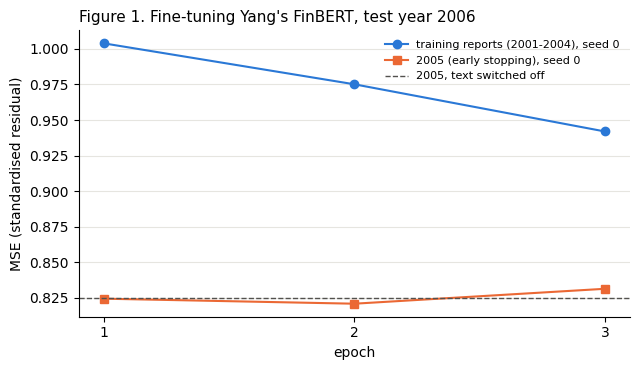

training: 40 chunks/s, 0.94 GPU-hours for 3 epochs


In [22]:
if (out / "alex-05-history.csv").exists():
    hist = pd.read_csv(out / "alex-05-history.csv")
    display(hist.round(4))
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    for seed, h in hist.groupby("seed"):
        ax.plot(h["epoch"], h["train_mse"], "o-", color="#2a78d6", label=f"training reports (2001-2004), seed {seed}")
        ax.plot(h["epoch"], h["val_mse"], "s-", color="#eb6834", label=f"2005 (early stopping), seed {seed}")
    ax.axhline(hist["val_mse_text_off"].iloc[0], color="#52514e", ls="--", lw=1, label="2005, text switched off")
    ax.set_xlabel("epoch"); ax.set_ylabel("MSE (standardised residual)")
    ax.set_xticks(sorted(hist["epoch"].unique()))
    ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8)
    ax.set_title("Figure 1. Fine-tuning Yang's FinBERT, test year 2006", fontsize=11, loc="left")
    fig.tight_layout(); plt.show()
    print(f"training: {hist['train_chunks'].sum() / hist['train_seconds'].sum():.0f} chunks/s, "
          f"{hist['train_seconds'].sum() / 3600:.2f} GPU-hours for {len(hist)} epochs")

## 6. What this shows

The results come from the saved run: one seed, test year 2006, paper window, 3 epochs on a Colab T4.

* **Fine-tuning gives the best result of any model in 2006, but not clearly better than the frozen ones.** The
  fine-tuned model changes the MSE by −1.51% against the straight line (0.0968 against 0.0982), and the paired
  bootstrap interval of the difference excludes zero (−0.0027 to −0.0004). Almost all of it is spread, so it comes
  from telling companies apart, not from the year. The best frozen models on the same reports are the attention
  network on Yang's CLS vectors (−1.23%) and the within-year ridge on them (−1.16%). The gap, 0.3 percentage
  points, is smaller than the spread between seeds of the frozen network in this year (−2.0% to −0.4%), and this is
  one seed, so it cannot be told apart from seed noise.
* **It learnt very little before it started to overfit** (Figure 1). On 2005, the year used for early stopping,
  the first epoch is no better than switching the text off (0.8244 against 0.8249), the second is 0.5% better, and
  the third is worse than switching it off (0.8314), while the training error keeps falling (1.00, 0.98, 0.94). So
  the epoch kept is the second, and with a third the model was already fitting noise in the training reports. This
  is what notebook 04 suggested: with about 11,000 training reports, there is little in the text for 110 million
  weights to learn before they overfit.
* **It is the most expensive model by far.** Training reads 40 chunks a second, against about 150 for only
  embedding them (notebook 04), because every chunk goes through the encoder forwards and backwards; even reading
  only 4 chunks per report, an epoch takes 19 minutes, and scoring 2005 after it another 8.5. The run used about
  1.5 GPU-hours for one test year and one seed, against 15 minutes for all 60 runs of the frozen network on Yang's
  vectors. Peak memory was 3.0 GB, so memory was not the limit.

**Speed.** At 1000 times the data, one epoch would be about 45 million training chunks, or about 310 T4-hours. Unlike
embedding, the training steps are not independent: every step updates the same weights. The work can still be
split across GPUs by giving each one part of every batch (data parallelism), but after every step the gradients,
110 million numbers, have to be added up across all of them and sent back. That is the reduce step of lecture 09.2,
and its cost grows with the number of GPUs, so fine-tuning scales much less well than the embedding, which is
embarrassingly parallel (lecture 09.1).

Fine-tuning is the one test in this project that changes the vectors themselves, and it does not change the answer.
It does no measurably better than the frozen models on 2006, and it overfits within three epochs. Showing a real
gain would need more seeds and more test years, at about 1.5 GPU-hours each, and the training curve gives little
reason to expect one.

## References

- Devlin, J., Chang, M.-W., Lee, K. & Toutanova, K. (2019). BERT: Pre-training of deep bidirectional transformers for language understanding. *NAACL-HLT 2019*. https://aclanthology.org/N19-1423/
- Loshchilov, I. & Hutter, F. (2019). Decoupled weight decay regularization. *ICLR 2019*.
- Micikevicius, P. et al. (2018). Mixed precision training. *ICLR 2018*.
- Sun, C., Qiu, X., Xu, Y. & Huang, X. (2019). How to fine-tune BERT for text classification? *CCL 2019*. arXiv:1905.05583
- Xia, B., Rawte, V. D., Zaki, M. J. & Gupta, A. (2022). FETILDA: An effective framework for fin-tuned embeddings for long financial text documents. *arXiv:2206.06952*.
- Yang, Y., Uy, M. C. S. & Huang, A. (2020). FinBERT: A pretrained language model for financial communications. *arXiv:2006.08097*. Model: https://huggingface.co/yiyanghkust/finbert-pretrain

Course material (Data Science Toolbox, University of Bristol, 2026):

- Assessment 2 brief (pre-trained models, transfer learning, fine-tuning). https://dsbristol.github.io/dst/assets/assessments/Assessment2.pdf
- Lecture 05.2, Statistical Testing. https://dsbristol.github.io/dst/assets/slides/05.2-StatisticalTesting.pdf
- Lecture 06.1, Neural Networks 1 (loss functions, gradient descent). https://dsbristol.github.io/dst/assets/slides/06.1-Neural%20Networks%20Lecture%201.pdf
- Lecture 06.2, Neural Networks 2 (pooling layers). https://dsbristol.github.io/dst/assets/slides/06.2-Neural%20Networks%20Lecture%202.pdf
- Lecture 09.1, Introduction to Parallelism. https://dsbristol.github.io/dst/assets/slides/09.1-ParallelAlgorithms.pdf
- Lecture 09.2, Mapping, Reducing, and Computational Graphs. https://dsbristol.github.io/dst/assets/slides/09.2-ComputationalGraphs.pdf